# VP2 — Aprendizado de Máquina (PPGEP 2026.2) — Parte 2: RNN para prognóstico (RUL)

**Problema:** estimar a Vida Útil Remanescente (RUL, em ciclos) de motores turbofan do
sub-conjunto **FD001** do C-MAPSS (NASA, Saxena et al., 2008) a partir de janelas de leituras de sensores.
Regressão em séries temporais: entrada = janela de *W* ciclos × 14 sensores; saída = RUL (contínuo); perda = MSE.

Pipeline (seção 6 do enunciado): **Etapa 1** EDA → **Etapa 2** pré-processamento → **Etapa 3** arquitetura →
**Etapa 4** treinamento → **Etapa 5** Optuna (TPE + Hyperband) → **Etapa 6** avaliação no teste completo.

In [1]:
import os, time, random, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import optuna
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

DATA_DIR = os.path.join(os.environ.get("VP2_DATA", "data"), "CMAPSS")   # train_FD001.txt, test_FD001.txt, RUL_FD001.txt
FIG_DIR = "figuras"; os.makedirs(FIG_DIR, exist_ok=True)
MODEL_DIR = "modelos"; os.makedirs(MODEL_DIR, exist_ok=True)

RUL_CLIP = 130           # target piece-wise linear
N_TRIALS = 30            # trials do Optuna
SEARCH_EPOCHS = 40       # máx. de épocas por trial (recurso máximo do Hyperband)
FINAL_EPOCHS = 150
BATCH = 256
if os.environ.get("VP2_FAST"):   # modo de teste rápido do código (não usado nos resultados)
    N_TRIALS, SEARCH_EPOCHS, FINAL_EPOCHS = 3, 3, 3

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), dpi=130, bbox_inches="tight"); plt.show()

print("TensorFlow", tf.__version__, "| Optuna", optuna.__version__)

I0000 00:00:1792511995.695768   12871 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792511995.696456   12871 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | Optuna 5.0.0


I0000 00:00:1792511996.703118   12871 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792511996.703839   12871 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Etapa 1 — Carregamento e Análise Exploratória (EDA)
### 1. Carregar train_FD001, test_FD001 e RUL_FD001

In [2]:
COLS = ["unit_id", "cycle", "setting_1", "setting_2", "setting_3"] + [f"s{i}" for i in range(1, 22)]
read = lambda f: pd.read_csv(os.path.join(DATA_DIR, f), sep=r"\s+", header=None, names=COLS)
train = read("train_FD001.txt")
test = read("test_FD001.txt")
rul_test = pd.read_csv(os.path.join(DATA_DIR, "RUL_FD001.txt"), sep=r"\s+", header=None, names=["RUL"])
rul_test["unit_id"] = np.arange(1, len(rul_test) + 1)
print("treino:", train.shape, "| teste:", test.shape, "| RUL teste:", rul_test.shape)
print("motores treino:", train.unit_id.nunique(), "| motores teste:", test.unit_id.nunique())
display(train.head())

treino: (20631, 26) | teste: (13096, 26) | RUL teste: (100, 2)
motores treino: 100 | motores teste: 100


,unit_id,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


### 2. Distribuição do número de ciclos por motor

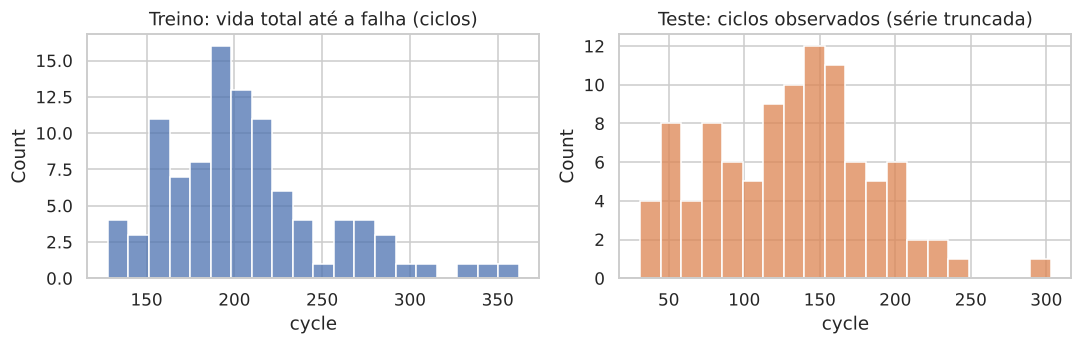

       treino (vida total)  teste (observado)  RUL real do teste
count                100.0              100.0              100.0
mean                 206.3              131.0               75.5
std                   46.3               53.6               41.8
min                  128.0               31.0                7.0
25%                  177.0               88.8               32.8
50%                  199.0              133.5               86.0
75%                  229.2              164.2              112.2
max                  362.0              303.0              145.0


In [3]:
life_tr = train.groupby("unit_id").cycle.max()
life_te = test.groupby("unit_id").cycle.max()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
sns.histplot(life_tr, bins=20, ax=ax[0]); ax[0].set_title("Treino: vida total até a falha (ciclos)")
sns.histplot(life_te, bins=20, ax=ax[1], color="C1"); ax[1].set_title("Teste: ciclos observados (série truncada)")
savefig("rnn_ciclos_por_motor.png")
print(pd.DataFrame({"treino (vida total)": life_tr.describe(), "teste (observado)": life_te.describe(),
                    "RUL real do teste": rul_test.RUL.describe()}).round(1))

No treino a vida até a falha varia de 128 a 362 ciclos (média ≈ 206). No teste as séries são truncadas
(31 a 303 ciclos observados) e o RUL verdadeiro varia de 7 a 145 ciclos. O motor de teste mais curto tem
apenas 31 ciclos — isso limita o tamanho de janela *W* que pode ser usado sem preenchimento (padding).

### 3. Séries temporais de sensores (3 sensores × 3 motores)

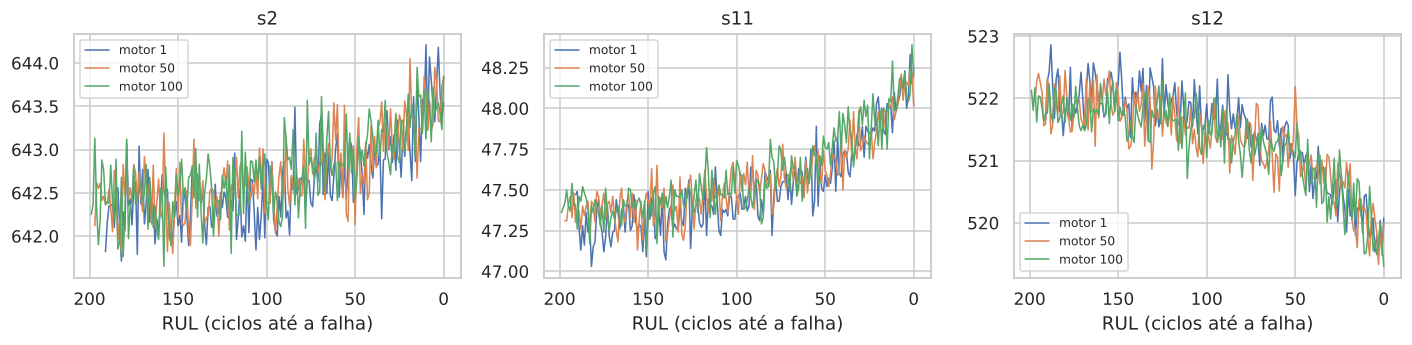

In [4]:
train["RUL"] = train.groupby("unit_id").cycle.transform("max") - train.cycle   # RUL(t) = T_falha − t
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for a, s in zip(axes, ["s2", "s11", "s12"]):
    for u in [1, 50, 100]:
        d = train[train.unit_id == u]
        a.plot(d.RUL, d[s], label=f"motor {u}", lw=1)
    a.invert_xaxis(); a.set_xlabel("RUL (ciclos até a falha)"); a.set_title(s); a.legend(fontsize=8)
savefig("rnn_series_sensores.png")

Os sensores ficam estáveis (apenas ruído) durante boa parte da vida e passam a variar de forma
monótona e acelerada perto da falha: **T24 (s2)** e **Ps30 (s11)** sobem, **phi (s12)** desce.
Isso justifica o *clipping* do alvo: no início da vida os sensores não distinguem RUL = 300 de RUL = 200.

### 4. Variância de cada sensor e identificação dos 7 sensores constantes

In [5]:
sensors = [f"s{i}" for i in range(1, 22)]
var = pd.DataFrame({"desvio padrão": train[sensors].std(), "nº valores distintos": train[sensors].nunique(),
                    "corr. com RUL": train[sensors].corrwith(train.RUL)}).sort_values("desvio padrão")
display(var.round(5))
CONST = var.index[:7].tolist()
USEFUL = [s for s in sensors if s not in CONST]
print("Sensores constantes (removidos):", CONST)
print("Sensores úteis (14):", USEFUL)
print("Desvio padrão das condições operacionais:", train[["setting_1", "setting_2", "setting_3"]].std().round(5).to_dict())

,desvio padrão,nº valores distintos,corr. com RUL
s1,0.00000,1,NaN
s10,0.00000,1,NaN
s19,0.00000,1,NaN
s18,0.00000,1,NaN
s16,0.00000,1,-0.00000
s5,0.00000,1,0.00000
s6,0.00139,2,-0.12835
s15,0.03751,1918,-0.64267
s8,0.07099,53,-0.56397
s13,0.07192,56,-0.56257


Sensores constantes (removidos): ['s1', 's10', 's19', 's18', 's16', 's5', 's6']
Sensores úteis (14): ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
Desvio padrão das condições operacionais: {'setting_1': 0.00219, 'setting_2': 0.00029, 'setting_3': 0.0}


Os sensores **s1, s5, s6, s10, s16, s18 e s19** têm (praticamente) um único valor em todas as trajetórias
(s6 só tem 2 valores distintos, com desvio ~0,001): não carregam informação sobre a degradação e são removidos.
As 3 condições operacionais também são removidas: o FD001 tem uma única condição (cruzeiro), e seus
valores são só ruído. Restam os **14 sensores** da tabela 4.3 do enunciado.

### 5. Matriz de correlação dos 14 sensores úteis

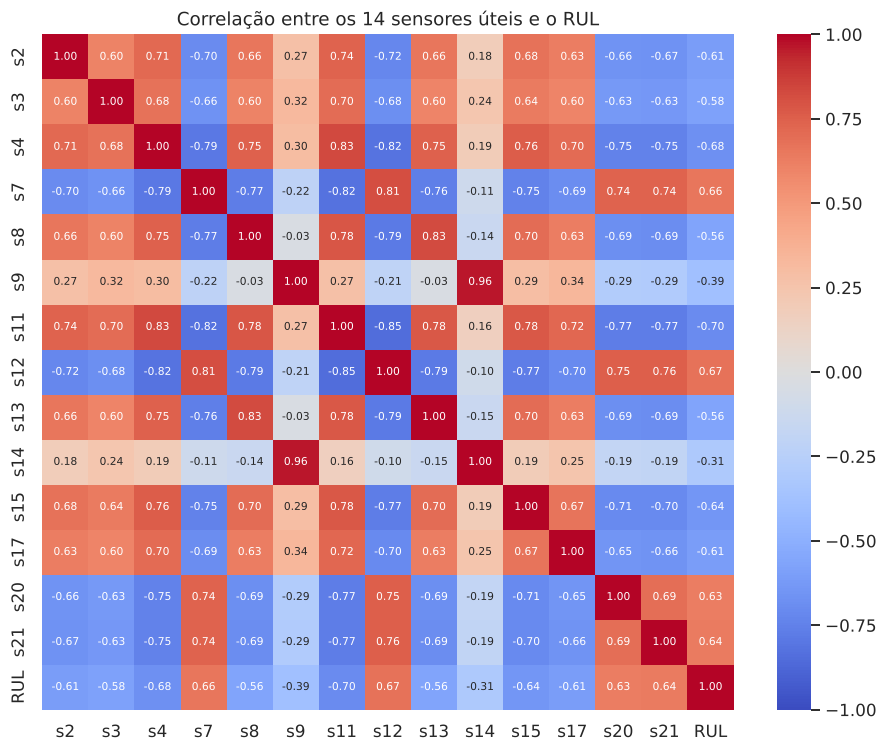

In [6]:
plt.figure(figsize=(8.5, 7))
sns.heatmap(train[USEFUL + ["RUL"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlação entre os 14 sensores úteis e o RUL")
savefig("rnn_correlacao.png")

Há dois grupos fortemente correlacionados: sensores que **crescem** com a degradação (s2, s3, s4, s8, s11,
s13, s15, s17) e que **decrescem** (s7, s12, s20, s21). Os pares s9–s14 (velocidades do *core*) têm
correlação ≈ 0,96 entre si. A redundância é alta, mas mantemos os 14 sensores como pede o enunciado — a
RNN combina essas medidas ruidosas e redundantes, o que funciona como uma média que reduz o ruído.

## Etapa 2 — Pré-processamento
### 6. Remoção de sensores constantes e de `unit_id` como feature
`unit_id` continua no DataFrame só para agrupar as janelas por motor; não entra na entrada da rede.
### 11. Divisão treino/validação **por motor** (80/20)
Fazemos a divisão antes da normalização para poder ajustar o scaler apenas nos motores de treino.
A divisão por motor garante que nenhum motor tenha janelas em treino e validação ao mesmo tempo
(janelas sobrepostas do mesmo motor são quase idênticas — dividir por amostra vazaria informação).

In [7]:
rng = np.random.default_rng(SEED)
units = train.unit_id.unique()
val_units = np.sort(rng.choice(units, size=int(0.2 * len(units)), replace=False))
tr_units = np.setdiff1d(units, val_units)
assert len(np.intersect1d(tr_units, val_units)) == 0
print(f"{len(tr_units)} motores de treino, {len(val_units)} motores de validação:", val_units)

80 motores de treino, 20 motores de validação: [ 8  9 13 18 37 46 48 50 55 62 64 69 72 74 76 84 85 87 90 95]


### 7. Normalização MinMax — *fit* somente no treino
O scaler é ajustado só com os motores de treino e depois aplicado a validação e teste. Fazer *fit* no teste
usaria mínimos/máximos de dados que, na prática, ainda não existem no momento da previsão (vazamento de
informação): o modelo seria avaliado com uma escala "adaptada" ao teste e a métrica ficaria otimista.
Além disso, como o teste é truncado (motores mais saudáveis), seus min/max diferem dos do treino, e um
scaler próprio colocaria o mesmo valor físico em posições diferentes da escala.

In [8]:
scaler = MinMaxScaler().fit(train.loc[train.unit_id.isin(tr_units), USEFUL])
train_n = train.copy(); test_n = test.copy()
train_n[USEFUL] = scaler.transform(train[USEFUL])
test_n[USEFUL] = scaler.transform(test[USEFUL])

### 8–9. RUL de cada linha do treino + *clipping* piece-wise linear (máx. 130)

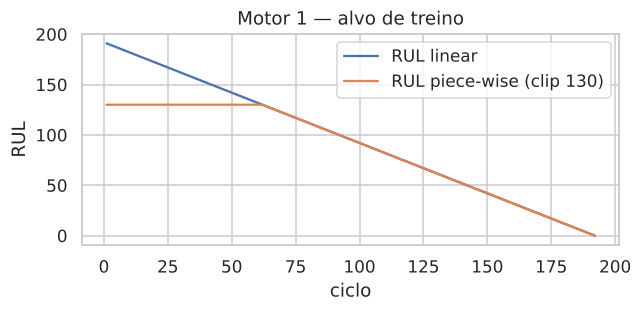

In [9]:
train_n["RUL_clip"] = train_n.RUL.clip(upper=RUL_CLIP)
d = train_n[train_n.unit_id == 1]
plt.figure(figsize=(6, 3))
plt.plot(d.cycle, d.RUL, label="RUL linear"); plt.plot(d.cycle, d.RUL_clip, label=f"RUL piece-wise (clip {RUL_CLIP})")
plt.xlabel("ciclo"); plt.ylabel("RUL"); plt.title("Motor 1 — alvo de treino"); plt.legend()
savefig("rnn_rul_clip.png")

### 10. Janelas deslizantes (stride = 1)
Para cada motor, uma janela de *W* ciclos desliza ciclo a ciclo; cada janela gera uma amostra (W, 14) cujo
alvo é o RUL (clipado) do **último** ciclo da janela. No teste usa-se apenas a **última janela** de cada
motor (o RUL verdadeiro se refere ao último ciclo observado). Motores de teste com menos de *W* ciclos
recebem *padding* repetindo a primeira leitura (só acontece se W > 31).

**Efeito de W:** janelas maiores dão à rede mais contexto da tendência de degradação e filtram o ruído,
mas (i) reduzem o nº de amostras de treino (cada motor perde W−1 janelas), (ii) aumentam o custo e
(iii) exigem padding nos motores de teste curtos. Janelas pequenas reagem rápido, mas são ruidosas.
W entra no espaço de busca do Optuna (Etapa 5) e o efeito é quantificado lá.

In [10]:
def make_windows(df, W, units_sel, target="RUL_clip"):
    X, y = [], []
    for u in units_sel:
        a = df.loc[df.unit_id == u, USEFUL].values
        t = df.loc[df.unit_id == u, target].values
        for end in range(W, len(a) + 1):
            X.append(a[end - W:end]); y.append(t[end - 1])
    return np.asarray(X, np.float32), np.asarray(y, np.float32)

def make_test_windows(df, W):
    X = []
    for u in sorted(df.unit_id.unique()):
        a = df.loc[df.unit_id == u, USEFUL].values
        if len(a) < W:
            a = np.vstack([np.repeat(a[:1], W - len(a), axis=0), a])
        X.append(a[-W:])
    return np.asarray(X, np.float32)

def get_data(W):
    Xtr, ytr = make_windows(train_n, W, tr_units)
    Xval, yval = make_windows(train_n, W, val_units)
    Xte = make_test_windows(test_n, W)
    return Xtr, ytr, Xval, yval, Xte

W0 = 30
Xtr, ytr, Xval, yval, Xte = get_data(W0)
print(f"W={W0}: treino {Xtr.shape}, validação {Xval.shape}, teste {Xte.shape}")
for W in [20, 30, 40, 50]:
    n = sum(max(0, l - W + 1) for l in life_tr)
    print(f"  W={W}: {n} janelas de treino no total | motores de teste que precisam de padding: {(life_te < W).sum()}")

W=30: treino (14070, 30, 14), validação (3661, 30, 14), teste (100, 30, 14)
  W=20: 18731 janelas de treino no total | motores de teste que precisam de padding: 0
  W=30: 17731 janelas de treino no total | motores de teste que precisam de padding: 0
  W=40: 16731 janelas de treino no total | motores de teste que precisam de padding: 4
  W=50: 15731 janelas de treino no total | motores de teste que precisam de padding: 7


## Etapa 3 — Arquitetura do modelo RNN

- **12. Célula:** LSTM como modelo de partida. A SimpleRNN sofre com gradientes que desaparecem em janelas
  de 30+ passos; LSTM e GRU têm portões que preservam a informação da tendência lenta de degradação.
  A GRU tem menos parâmetros (2 portões) e é testada na comparação abaixo e no Optuna.
- **13–14.** 2 camadas recorrentes empilhadas com U = 64 neurônios cada (capacidade suficiente para
  14 entradas e ~14 mil janelas, sem superajuste excessivo).
- **15.** `return_sequences=True` nas camadas intermediárias (passa a sequência inteira para a próxima
  camada recorrente) e `False` na última (só o estado final vai para a cabeça densa).
- **16–17.** Cabeça MLP com Dense(ReLU) e saída **Dense(1, activation='linear')** — regressão sem limitação de faixa.
- **18.** Dropout após cada camada recorrente e na cabeça densa.
- **19.** Adam com lr = 1e-3 (valor padrão estável para RNNs; o ReduceLROnPlateau reduz quando estagna).
- **20.** Perda: MSE.

In [11]:
CELLS = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}

def build_rnn(W, cell="LSTM", n_layers=2, units=64, dropout=0.2, dense_units=32, lr=1e-3, n_features=14):
    model = keras.Sequential(name=f"{cell}_{n_layers}x{units}")
    model.add(keras.Input(shape=(W, n_features)))
    for i in range(n_layers):
        model.add(CELLS[cell](units, return_sequences=(i < n_layers - 1)))   # True nas intermediárias, False na última
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(dense_units, activation="relu"))
    model.add(layers.Dropout(dropout / 2))
    model.add(layers.Dense(1, activation="linear"))                          # saída linear (regressão)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="mean_squared_error",
                  metrics=[keras.metrics.RootMeanSquaredError(name="rmse")])
    return model

baseline = build_rnn(W0)
baseline.summary()

E0000 00:00:1792511999.138261   12871 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "LSTM_2x64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,361 (216.25 KB)

 Trainable params: 55,361 (216.25 KB)

 Non-trainable params: 0 (0.00 B)

## Etapa 4 — Treinamento
Callbacks: **EarlyStopping** (val_loss, patience = 15, restore_best_weights), **ReduceLROnPlateau**
(fator 0,5 após 5 épocas sem melhora) e **ModelCheckpoint** (salva o melhor modelo).

Baseline LSTM: 70 épocas em 223s | melhor val RMSE = 14.69


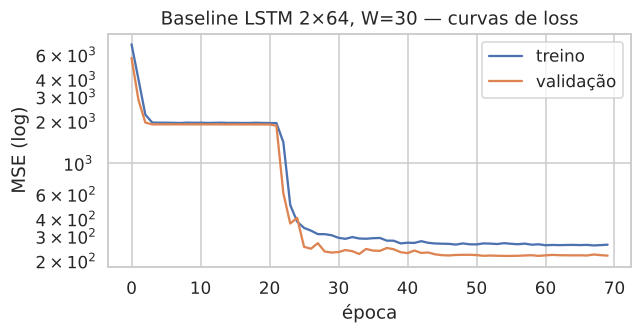

In [12]:
def callbacks(ckpt=None, patience=15):
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6)]
    if ckpt:
        cb.append(keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True))
    return cb

def plot_loss(h, title, fname):
    plt.figure(figsize=(6, 3.2))
    plt.plot(h.history["loss"], label="treino"); plt.plot(h.history["val_loss"], label="validação")
    plt.yscale("log"); plt.xlabel("época"); plt.ylabel("MSE (log)"); plt.title(title); plt.legend()
    savefig(fname)

t0 = time.time()
h_base = baseline.fit(Xtr, ytr, validation_data=(Xval, yval), epochs=FINAL_EPOCHS, batch_size=BATCH,
                      callbacks=callbacks(os.path.join(MODEL_DIR, "rnn_baseline.keras")), verbose=0)
print(f"Baseline LSTM: {len(h_base.history['loss'])} épocas em {time.time()-t0:.0f}s | "
      f"melhor val RMSE = {min(h_base.history['val_rmse']):.2f}")
plot_loss(h_base, "Baseline LSTM 2×64, W=30 — curvas de loss", "rnn_loss_baseline.png")

### Comparação dos tipos de célula (mesma arquitetura, W = 30)

In [13]:
cell_rows = []
for cell in ["SimpleRNN", "LSTM", "GRU"]:
    keras.utils.set_random_seed(SEED)
    m = build_rnn(W0, cell=cell)
    t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xval, yval), epochs=FINAL_EPOCHS, batch_size=BATCH, callbacks=callbacks(), verbose=0)
    cell_rows.append({"célula": cell, "parâmetros": m.count_params(), "épocas": len(h.history["loss"]),
                      "tempo (s)": time.time() - t0, "melhor val RMSE": min(h.history["val_rmse"])})
cell_cmp = pd.DataFrame(cell_rows).set_index("célula")
display(cell_cmp.round(2))

,parâmetros,épocas,tempo (s),melhor val RMSE
célula,,,,
SimpleRNN,15425,88,89.58,14.50
LSTM,55361,70,218.90,14.69
GRU,42433,34,114.33,14.21


## Etapa 5 — Busca de hiperparâmetros com Optuna (TPE + Hyperband)
Espaço de busca: tipo de célula, nº de camadas (1–3), neurônios por camada, dropout, learning rate e
tamanho da janela W. Objetivo: minimizar o RMSE de validação (motores de validação). A cada época o
val RMSE é reportado ao **HyperbandPruner**, que interrompe trials pouco promissores.

In [14]:
_data_cache = {}
def cached_data(W):
    if W not in _data_cache:
        _data_cache[W] = get_data(W)
    return _data_cache[W]

class OptunaPruning(keras.callbacks.Callback):
    def __init__(self, trial): super().__init__(); self.trial = trial; self.pruned = False
    def on_epoch_end(self, epoch, logs=None):
        self.trial.report(logs["val_rmse"], epoch)
        if self.trial.should_prune():
            self.pruned = True; self.model.stop_training = True

def objective(trial):
    p = dict(W=trial.suggest_categorical("W", [20, 30, 40, 50]),
             cell=trial.suggest_categorical("cell", ["SimpleRNN", "LSTM", "GRU"]),
             n_layers=trial.suggest_int("n_layers", 1, 3),
             units=trial.suggest_categorical("units", [32, 64, 96, 128]),
             dropout=trial.suggest_float("dropout", 0.0, 0.5),
             lr=trial.suggest_float("lr", 1e-4, 1e-2, log=True))
    Xtr_, ytr_, Xval_, yval_, _ = cached_data(p["W"])
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    m = build_rnn(**p)
    pr = OptunaPruning(trial)
    h = m.fit(Xtr_, ytr_, validation_data=(Xval_, yval_), epochs=SEARCH_EPOCHS, batch_size=BATCH,
              callbacks=callbacks(patience=8) + [pr], verbose=0)
    if pr.pruned:
        raise optuna.TrialPruned()
    return min(h.history["val_rmse"])

study = optuna.create_study(direction="minimize", study_name="rul_fd001",
                            storage="sqlite:///optuna_rnn.db", load_if_exists=False,
                            sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.HyperbandPruner(min_resource=5, max_resource=SEARCH_EPOCHS))
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS)
states = pd.Series([t.state.name for t in study.trials]).value_counts()
print(f"Optuna: {N_TRIALS} trials em {(time.time()-t0)/60:.1f} min | {states.to_dict()}")
print("Melhor val RMSE:", round(study.best_value, 3), "| parâmetros:", study.best_params)

Optuna: 30 trials em 61.9 min | {'PRUNED': 17, 'COMPLETE': 13}
Melhor val RMSE: 12.15 | parâmetros: {'W': 50, 'cell': 'GRU', 'n_layers': 2, 'units': 96, 'dropout': 0.297657264253799, 'lr': 0.0014465316072888278}


In [15]:
trials_df = study.trials_dataframe(attrs=("number", "value", "params", "state"))
trials_df.columns = [c.replace("params_", "") for c in trials_df.columns]
display(trials_df.sort_values("value").head(10).round(4))
trials_df.to_csv("optuna_trials_rnn.csv", index=False)

,number,value,W,cell,dropout,lr,n_layers,units,state
15,15,12.1502,50,GRU,0.2977,0.0014,2,96,COMPLETE
29,29,12.2261,50,GRU,0.1657,0.0016,2,128,COMPLETE
23,23,12.3370,50,GRU,0.3168,0.0035,2,128,COMPLETE
25,25,12.3663,50,GRU,0.2474,0.0020,2,96,COMPLETE
11,11,12.4118,50,GRU,0.3941,0.0032,3,128,COMPLETE
14,14,12.4321,50,GRU,0.3179,0.0016,2,128,COMPLETE
20,20,12.4839,50,GRU,0.1975,0.0034,2,128,COMPLETE
26,26,12.6119,50,GRU,0.1061,0.0061,2,96,COMPLETE
1,1,12.8832,50,GRU,0.0998,0.0011,1,128,COMPLETE
10,10,12.9386,50,GRU,0.4154,0.0084,2,128,COMPLETE


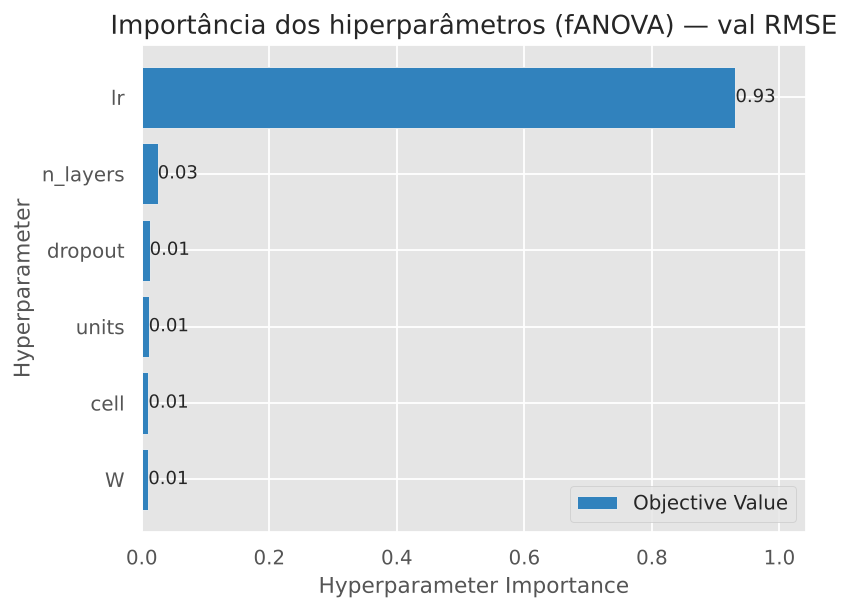

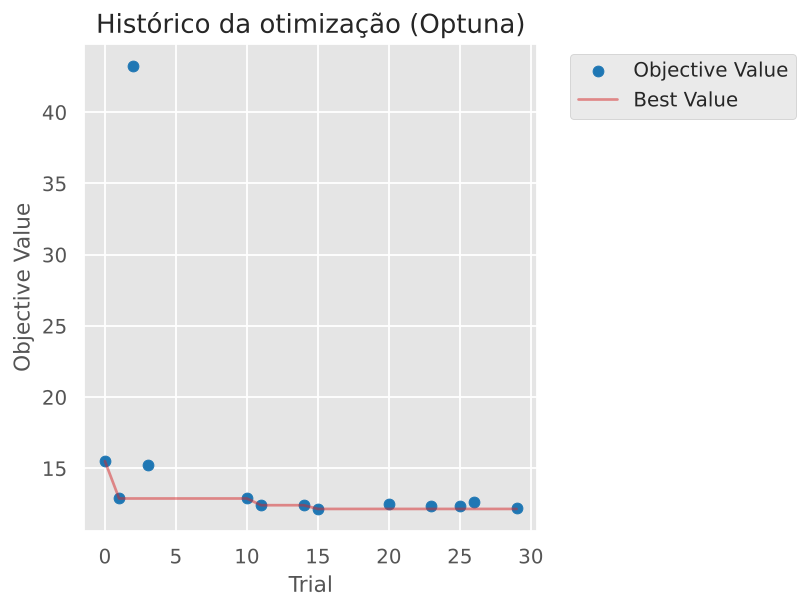

In [16]:
from optuna.visualization.matplotlib import plot_param_importances, plot_optimization_history
ax = plot_param_importances(study); ax._left_title.set_text(""); ax.set_title("Importância dos hiperparâmetros (fANOVA) — val RMSE")
savefig("rnn_optuna_importancia.png")
ax = plot_optimization_history(study); ax._left_title.set_text(""); ax.set_title("Histórico da otimização (Optuna)")
savefig("rnn_optuna_historico.png")

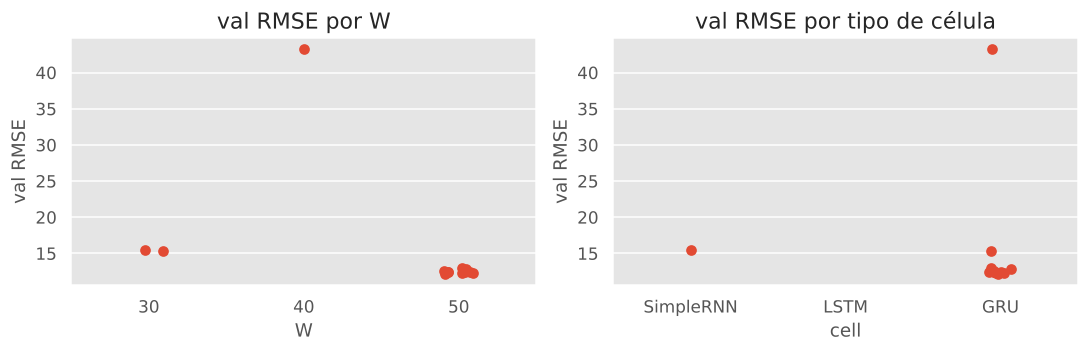

,min,median,count
W,,,
30,15.26,15.38,2
40,43.26,43.26,1
50,12.15,12.42,10


,min,median,count
cell,,,
GRU,12.15,12.46,12
SimpleRNN,15.50,15.50,1


In [17]:
# Efeito de W e do tipo de célula entre os trials completos
done = trials_df[trials_df.state == "COMPLETE"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
sns.stripplot(data=done, x="W", y="value", ax=ax[0], size=7); ax[0].set_ylabel("val RMSE"); ax[0].set_title("val RMSE por W")
sns.stripplot(data=done, x="cell", y="value", ax=ax[1], size=7, order=["SimpleRNN", "LSTM", "GRU"]); ax[1].set_ylabel("val RMSE")
ax[1].set_title("val RMSE por tipo de célula")
savefig("rnn_optuna_W_celula.png")
display(done.groupby("W").value.agg(["min", "median", "count"]).round(2))
display(done.groupby("cell").value.agg(["min", "median", "count"]).round(2))

### Treinamento final com os melhores hiperparâmetros

Model: "GRU_2x96"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 50, 96)         │        32,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 96)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 96)             │        55,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,265 (356.50 KB)

 Trainable params: 91,265 (356.50 KB)

 Non-trainable params: 0 (0.00 B)

Modelo final: 51 épocas em 338s


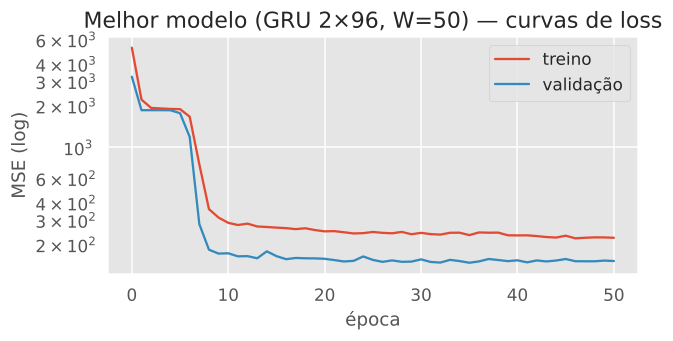

In [18]:
best = dict(study.best_params)
W_best = best["W"]
Xtr_b, ytr_b, Xval_b, yval_b, Xte_b = cached_data(W_best)
keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
best_model = build_rnn(**best)
best_model.summary()
t0 = time.time()
h_best = best_model.fit(Xtr_b, ytr_b, validation_data=(Xval_b, yval_b), epochs=FINAL_EPOCHS, batch_size=BATCH,
                        callbacks=callbacks(os.path.join(MODEL_DIR, "rnn_rul_fd001_best.keras")), verbose=0)
print(f"Modelo final: {len(h_best.history['loss'])} épocas em {time.time()-t0:.0f}s")
best_model = keras.models.load_model(os.path.join(MODEL_DIR, "rnn_rul_fd001_best.keras"))
plot_loss(h_best, f"Melhor modelo ({best['cell']} {best['n_layers']}×{best['units']}, W={W_best}) — curvas de loss",
          "rnn_loss_best.png")

## Etapa 6 — Avaliação no conjunto de teste completo (100 motores)
- **RMSE** e **MAE** contra o RUL verdadeiro (`RUL_FD001.txt`, sem clipping — avaliação mais rigorosa;
  também mostramos com o RUL real clipado em 130, convenção comum na literatura).
- **NASA Score** (Saxena et al., 2008): d = RUL_previsto − RUL_real; s = Σ exp(−d/13) − 1 para d < 0 e
  Σ exp(d/10) − 1 para d ≥ 0. Previsões **atrasadas** (d > 0, o modelo acha que o motor dura mais do
  que dura) são penalizadas mais fortemente por serem mais perigosas.

> Nota: o enunciado transcreve as constantes invertidas (10 para d < 0 e 13 para d ≥ 0). No artigo
> original (Eq. 11 de Saxena et al., 2008) a1 = 13 (antecipado) e a2 = 10 (atrasado), de modo que o atraso é
> o erro mais punido — que é a intenção declarada do score assimétrico. Calculamos as duas versões.

In [19]:
def nasa_score(y_true, y_pred, a_early=13.0, a_late=10.0):
    d = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.sum(np.where(d < 0, np.exp(-d / a_early) - 1, np.exp(d / a_late) - 1)))

y_true = rul_test.RUL.values.astype(float)

def evaluate(model, Xte_, name):
    y_pred = model.predict(Xte_, verbose=0).ravel()
    y_pred = np.clip(y_pred, 0, None)     # RUL negativo não tem significado físico
    return y_pred, {"modelo": name,
                    "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
                    "MAE": mean_absolute_error(y_true, y_pred),
                    "NASA Score (artigo)": nasa_score(y_true, y_pred),
                    "NASA Score (constantes do enunciado)": nasa_score(y_true, y_pred, a_early=10, a_late=13),
                    "RMSE (RUL real clip 130)": np.sqrt(mean_squared_error(np.minimum(y_true, RUL_CLIP), y_pred))}

base_model = keras.models.load_model(os.path.join(MODEL_DIR, "rnn_baseline.keras"))
y_pred_base, m_base = evaluate(base_model, Xte, f"Baseline LSTM 2×64 (W={W0})")
y_pred, m_best = evaluate(best_model, Xte_b, f"Optuna: {best['cell']} {best['n_layers']}×{best['units']} (W={W_best})")
test_metrics = pd.DataFrame([m_base, m_best]).set_index("modelo")
display(test_metrics.round(2))
test_metrics.round(3).to_csv("resultados_rnn_teste.csv")

,RMSE,MAE,NASA Score (artigo),NASA Score (constantes do enunciado),RMSE (RUL real clip 130)
modelo,,,,,
Baseline LSTM 2×64 (W=30),15.03,11.12,411.02,368.07,14.28
Optuna: GRU 2×96 (W=50),14.54,10.83,379.21,355.96,13.99


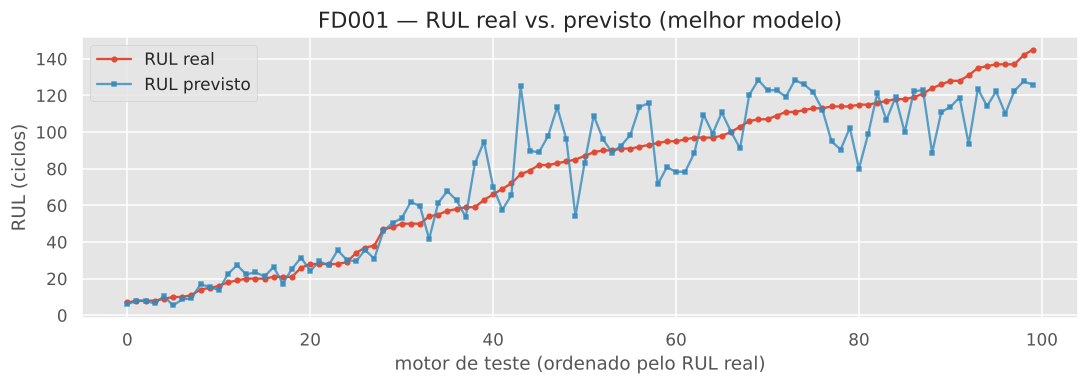

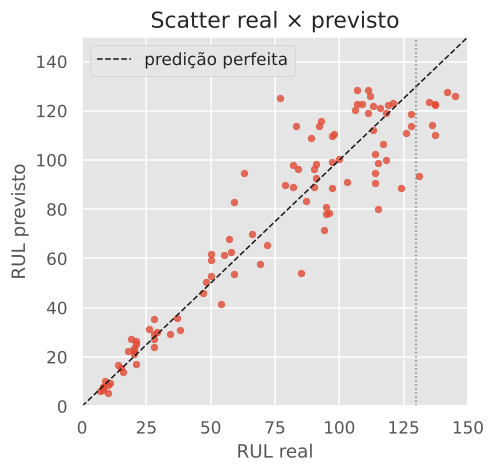

In [20]:
# 28. RUL real vs previsto (motores ordenados pelo RUL real)
order = np.argsort(y_true)
plt.figure(figsize=(10, 3.6))
plt.plot(y_true[order], "o-", ms=3, label="RUL real")
plt.plot(y_pred[order], "s-", ms=3, alpha=0.8, label="RUL previsto")
plt.xlabel("motor de teste (ordenado pelo RUL real)"); plt.ylabel("RUL (ciclos)"); plt.legend()
plt.title("FD001 — RUL real vs. previsto (melhor modelo)")
savefig("rnn_real_vs_previsto.png")

# 29. Scatter real x previsto com diagonal de predição perfeita
plt.figure(figsize=(4.6, 4.4))
lim = [0, max(y_true.max(), y_pred.max()) + 5]
plt.scatter(y_true, y_pred, s=18, alpha=0.8)
plt.plot(lim, lim, "k--", lw=1, label="predição perfeita")
plt.axvline(RUL_CLIP, color="gray", ls=":", lw=1)
plt.xlim(lim); plt.ylim(lim); plt.xlabel("RUL real"); plt.ylabel("RUL previsto"); plt.legend()
plt.title("Scatter real × previsto")
savefig("rnn_scatter.png")

### Análise dos erros — quando o modelo erra mais?

,n,erro_medio,MAE,RMSE
faixa RUL real,,,,
0–25,19,0.94,2.69,3.37
25–50,14,1.72,4.36,5.52
50–75,10,4.61,11.73,14.61
75–100,24,4.88,14.47,18.21
100–125,22,-2.56,13.97,16.73
125–150,11,-18.05,18.05,19.64


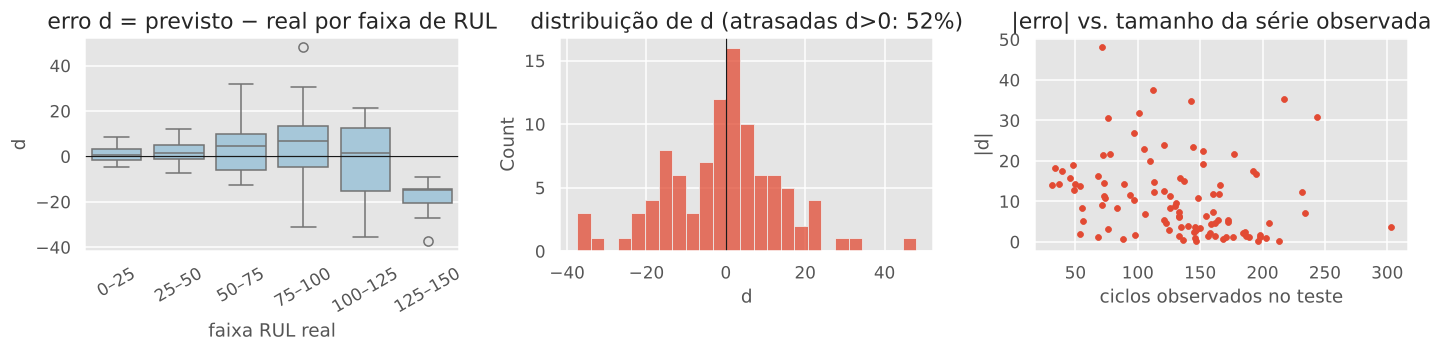

,unit_id,RUL_real,RUL_prev,ciclos_obs,d,faixa RUL real
66,67,77.0,125.000000,71,48.0,75–100
72,73,131.0,93.500000,112,-37.5,125–150
11,12,124.0,88.599998,217,-35.4,100–125
29,30,115.0,80.099998,143,-34.9,100–125
78,79,63.0,94.900002,101,31.9,50–75
92,93,85.0,54.099998,244,-30.9,75–100
14,15,83.0,113.699997,76,30.7,75–100
95,96,137.0,110.099998,97,-26.9,125–150


In [21]:
err = pd.DataFrame({"unit_id": rul_test.unit_id, "RUL_real": y_true, "RUL_prev": y_pred,
                    "ciclos_obs": life_te.values})
err["d"] = err.RUL_prev - err.RUL_real
err["faixa RUL real"] = pd.cut(err.RUL_real, [0, 25, 50, 75, 100, 125, 150],
                               labels=["0–25", "25–50", "50–75", "75–100", "100–125", "125–150"])
by_bin = err.groupby("faixa RUL real", observed=True).agg(n=("d", "size"), erro_medio=("d", "mean"),
                                                          MAE=("d", lambda x: x.abs().mean()),
                                                          RMSE=("d", lambda x: np.sqrt((x ** 2).mean())))
display(by_bin.round(2))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
sns.boxplot(data=err, x="faixa RUL real", y="d", ax=ax[0], color="#9ecae1"); ax[0].axhline(0, c="k", lw=0.8)
ax[0].set_title("erro d = previsto − real por faixa de RUL"); ax[0].tick_params(axis="x", rotation=30)
sns.histplot(err.d, bins=25, ax=ax[1]); ax[1].axvline(0, c="k", lw=0.8)
ax[1].set_title(f"distribuição de d (atrasadas d>0: {(err.d > 0).mean():.0%})")
ax[2].scatter(err.ciclos_obs, err.d.abs(), s=15); ax[2].set_xlabel("ciclos observados no teste"); ax[2].set_ylabel("|d|")
ax[2].set_title("|erro| vs. tamanho da série observada")
savefig("rnn_analise_erros.png")
display(err.reindex(err.d.abs().sort_values(ascending=False).index).head(8).round(1))

### Discussão

**Resultado.** O melhor modelo (Optuna) é uma **GRU com 2 camadas de 96 neurônios, W = 50, dropout ≈ 0,30 e lr ≈ 1,4·10⁻³**. No teste completo (100 motores), ela teve **RMSE = 14,54, MAE = 10,83 e NASA Score = 379**, contra RMSE 15,03 / MAE 11,12 / Score 411 da LSTM de partida (2×64, W = 30). Esses valores estão na faixa reportada na literatura para FD001 com redes recorrentes (RMSE ≈ 12–16).

**Escolha de W.** Os 10 melhores trials usam todos W = 50 (val RMSE de 12,2 a 12,9), enquanto os trials com W = 30 ficaram em torno de 15,3. Janelas mais longas deixam a rede ver mais da tendência de degradação e filtram o ruído dos sensores. O custo é ter 2.000 janelas de treino a menos (15.731 contra 17.731) e precisar de padding em 7 dos 100 motores de teste (os que têm menos de 50 ciclos observados). Mesmo com esse padding, o ganho de contexto compensou.

**Tipo de célula.** Com a mesma arquitetura (2×64, W = 30), as três células ficaram próximas na validação: GRU 14,21, SimpleRNN 14,50 e LSTM 14,69. Com janelas de 30 passos, o problema de gradiente que desaparece na SimpleRNN ainda é pequeno. Mesmo assim, a GRU convergiu em menos épocas (34, contra 70 da LSTM e 88 da SimpleRNN) e tem cerca de 23% menos parâmetros que a LSTM. Por isso o TPE concentrou a busca na GRU: 12 dos 13 trials completos usam GRU.

**Importância dos hiperparâmetros.** Pela fANOVA, o **learning rate** responde por cerca de 93% da variação do val RMSE. O nº de camadas tem cerca de 3%, e os demais hiperparâmetros cerca de 1% cada. Isso acontece porque o treino passa por um **platô inicial**: nas primeiras épocas a rede prevê praticamente a média do RUL (val RMSE ≈ 43, ou seja, MSE ≈ 1.850). Só depois ela "descobre" a tendência dos sensores e o erro cai bruscamente (curva de loss acima). Com lr muito baixo ou muito alto, a rede fica presa nesse platô. Vários trials podados (17 de 30) estavam nessa situação com valor ≈ 43. Uma limitação do Hyperband aqui é que modelos que demoram a sair do platô podem ser podados antes de mostrar seu potencial.

**Quando o modelo erra mais?**
- **O erro cresce com o RUL real.** Para RUL < 50 o RMSE fica entre 3 e 6 ciclos: perto da falha, a degradação já é visível nos sensores. Essa é justamente a região em que a decisão de manutenção importa. Entre 75 e 125 o RMSE sobe para 16–18 ciclos.
- **Acima de 125 ciclos o modelo sempre subestima** (erro médio −18). É o efeito esperado do clipping em 130: o modelo nunca prevê mais que cerca de 130. Esse é um erro **conservador** (antecipado), e o NASA Score o pune menos.
- Os maiores erros individuais aparecem em motores com **poucos ciclos observados** (por exemplo, o motor 67, com 71 ciclos: real 77, previsto 125). Com séries curtas, a janela ainda está na fase "saudável", e o modelo tende a prever um RUL alto.
- A distribuição de d é aproximadamente simétrica (52% das previsões atrasadas). Para uso real, seria possível deslocar as previsões alguns ciclos para baixo, trocando um pouco de RMSE por um NASA Score menor e mais segurança.

In [22]:
print("Modelo salvo para inferência:", os.path.join(MODEL_DIR, "rnn_rul_fd001_best.keras"))
print("Hiperparâmetros:", best)

Modelo salvo para inferência: modelos/rnn_rul_fd001_best.keras
Hiperparâmetros: {'W': 50, 'cell': 'GRU', 'n_layers': 2, 'units': 96, 'dropout': 0.297657264253799, 'lr': 0.0014465316072888278}
